# First Assignment - Business Process Prediction Simulation, and Optimization - Winter Semester 2026/2027

### Milena Fernanda Rivera Hernández

### **3.1 Technical Setup and Preliminaries**

In [1]:
# First we will list all the libraries that we will use and for what purpose

# Process mining
import pm4py

# Data frames handling
import pandas as pd

# For defining graph axes
import numpy as np

# Visualizations for additional stats
import matplotlib.pyplot as plt



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




### **3.2 Simple Event Log Analysis**

In [3]:
log = pm4py.read_xes("data_BPIChallenge2017_1_all/BPI Challenge 2017.xes.gz") 
df = pm4py.convert_to_dataframe(log)



/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 31509/31509 [01:27<00:00, 359.10it/s]


In [7]:
print(df.shape)
df.head(5)

(1202267, 19)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1673366067,withdraw,2016-01-01 09:52:36.392000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1493664571,schedule,2016-01-01 09:52:36.403000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
print(df["time:timestamp"].dtype)

datetime64[us, UTC]


In [22]:
# To report simple statistics about the data log we must map each 'column/attribute'
case = "case:concept:name"
act = "concept:name"
timestamp = "time:timestamp"
resource = "org:resource"
lifec = "lifecycle:transition"

In [23]:
# Number of cases 
num_cases = df[case].nunique()
print(num_cases) # 31509

31509


In [24]:
# Number of events
num_events = len(df)
print(num_events) # 1202267

1202267


In [25]:
# Number of process variants
num_proc_var = len(pm4py.get_variants(df))
print(num_proc_var)

15930


In [62]:
# Number of distinct case and event attribute labels

# For case
# First we must figure out the attribute labels
case_attributes = [col for col in df.columns if col.startswith("case:")]
# Check line
print(case_attributes)

num_dist_case_labels = len(case_attributes)
print(num_dist_case_labels)

# For event

# NOTE: Metadata lists only the global attributes that every event has. So if we add offer-related ones we have more.
# We should define in which ones we are interested in (global only for example). 
global_categorical_events = ["Action", "EventID", "EventOrigin","concept:name", "lifecycle:transition", "org:resource", "time:timestamp"] # EventID
#event_attributes = [c for c in global_categorical_events if c in df.columns] # 7 attributes

# Real attributes
event_attributes = [c for c in df.columns if not c.startswith("case:") and not c.startswith("@@")] # 15 attributes

# categorical event attributes = non-numeric, non-datetime event-level columns
categorical_event_attributes = df[event_attributes].select_dtypes(include=['object', 'str', 'category']).columns 

# Check line
print(event_attributes)

num_dist_event_labels = len(event_attributes)
print(num_dist_event_labels)

print(categorical_event_attributes)
print(len(categorical_event_attributes))

['case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount']
4
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']
15
Index(['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID',
       'lifecycle:transition', 'Accepted', 'Selected', 'OfferID'],
      dtype='str')
9


In [61]:
# Mean and standard deviation of case length

# First we must figure out events per case
case_len = df.groupby(case).size()

# Mean
cl_mean = case_len.mean()
# Check line
print(cl_mean) # 38.15

# STD
cl_std = case_len.std()
# Check line
print(cl_std) # 16.715

38.15630454790695
16.71530805656438


In [37]:
# Mean and standard deviation of case duration 

# First we must calculate the case duration
# We extract the corresponding timestamps
case_timestamp = df.groupby(case)[timestamp]
durationn = (case_timestamp.max() - case_timestamp.min()).dt.total_seconds() # we should keep it in our finnest granularity which are seconds for further calculations

# days ******

# Mean
mean_days = durationn.mean() / 86400
# Check line
print(mean_days)

# STD
std_days = durationn.std() / 86400
# Check line
print(std_days)

# minutes ****

# Mean
mean_minutes = durationn.mean() / 60
# Check line
print(mean_minutes)

# STD
std_minutes = durationn.std() / 60
# Check line
print(std_minutes)

# seconds *****

# Mean
mean_secs = durationn.mean()
# Check line
print(mean_secs)

# STD
std_secs = durationn.std()
# Check line
print(std_secs)


21.899605591087365
13.1692325332843
31535.432051165804
18963.694847929393
1892125.9230699483
1137821.6908757635


In [42]:
# Number of categorical event attributes
num_cat_events_att = len(categorical_event_attributes)
# Check line
print(num_cat_events_att)

9


In [60]:
# Table with the required statistics

table_4_stats = pd.DataFrame({
    "Statistic": ["Number of cases",
                  "Number of events",
                  "Number of process variants",
                  "Number of distinct case attribute labels",
                  "Number of distinct event attribute labels",
                  "Case length mean", 
                  "Case length std", 
                  "Case duration mean (days)",
                  "Case duration std (days)",
                  "Case duration mean (minutes)",
                  "Case duration std (minutes)",
                  "Case duration mean (seconds)",
                  "Case duration std (seconds)",
                  "Number of categorical event attributes"],
    "Value" :[f"{num_cases:,}",
              f"{num_events:,}",
              f"{num_proc_var:,}",
              num_dist_case_labels,
              num_dist_event_labels,
              f"{cl_mean:.3f}",
              f"{cl_std:.3f}",
              f"{mean_days:.3f}",
              f"{std_days:.3f}",
              f"{mean_minutes:,.3f}",
              f"{std_minutes:,.3f}",
              f"{mean_secs:,.3f}",
              f"{std_secs:,.3f}",
              num_cat_events_att]})

display(table_4_stats)


,Statistic,Value
0,Number of cases,"31,509"
1,Number of events,"1,202,267"
2,Number of process variants,"15,930"
3,Number of distinct case attribute labels,4
4,Number of distinct event attribute labels,15
5,Case length mean,38.156
6,Case length std,16.715
7,Case duration mean (days),21.900
8,Case duration std (days),13.169
9,Case duration mean (minutes),"31,535.432"


#### Additional Statistics

In [65]:
# For what I intent to add as additional statistics it is required a one case-level table so we must build it first

# Access possible actions
print(df[act].unique())


# NOTE: df is sorted by case and timestamp

# duration in days must be calculated using the previous durationn variable
dur_days = durationn / 86400 

# distinct cases can be obtain grouping by the case columns
cases = df.groupby(case).agg(loan_goal=("case:LoanGoal", "first"),
                             app_type=("case:ApplicationType", "first"),
                             amount=("case:RequestedAmount", "first"),
                             n_events=(act, "size"))

cases["duration_days"] = dur_days # NOTE: it is aligned by case ID

# NOTE: The outcome is the last of these activities in each case
outcome_acts = ["A_Pending", "A_Denied", "A_Cancelled"]
last_outcome = (df[df[act].isin(outcome_acts)].groupby(case)[act].last())

# NOTE: 98 cases are applications still open when the log ends, so “No decision yet” says what they are.
cases["outcome"] = last_outcome.reindex(cases.index).fillna("No decision yet")

print(cases["outcome"].value_counts())  

<StringArray>
[      'A_Create Application',                'A_Submitted',
             'W_Handle leads',     'W_Complete application',
                  'A_Concept',                 'A_Accepted',
             'O_Create Offer',                  'O_Created',
   'O_Sent (mail and online)',        'W_Call after offers',
                 'A_Complete',                'A_Cancelled',
                'O_Cancelled',     'W_Validate application',
               'A_Validating',                 'O_Returned',
                 'O_Accepted',                  'A_Pending',
    'W_Call incomplete files',               'A_Incomplete',
                   'A_Denied',                  'O_Refused',
       'O_Sent (online only)',   'W_Assess potential fraud',
    'W_Shortened completion ', 'W_Personal Loan collection']
Length: 26, dtype: str
outcome
A_Pending          17228
A_Cancelled        10431
A_Denied            3752
No decision yet       98
Name: count, dtype: int64


In [66]:
display(cases[:5]) # Line just to visualise the final table

,loan_goal,app_type,amount,n_events,duration_days,outcome
case:concept:name,,,,,,
Application_1000086665,"Other, see explanation",New credit,5000.0,22,32.585593,A_Cancelled
Application_1000158214,Home improvement,New credit,12500.0,25,8.033037,A_Pending
Application_1000311556,Car,New credit,45000.0,18,30.586242,A_Cancelled
Application_1000334415,"Other, see explanation",New credit,5000.0,40,13.629359,A_Denied
Application_1000339879,Existing loan takeover,New credit,37500.0,51,12.843500,A_Pending


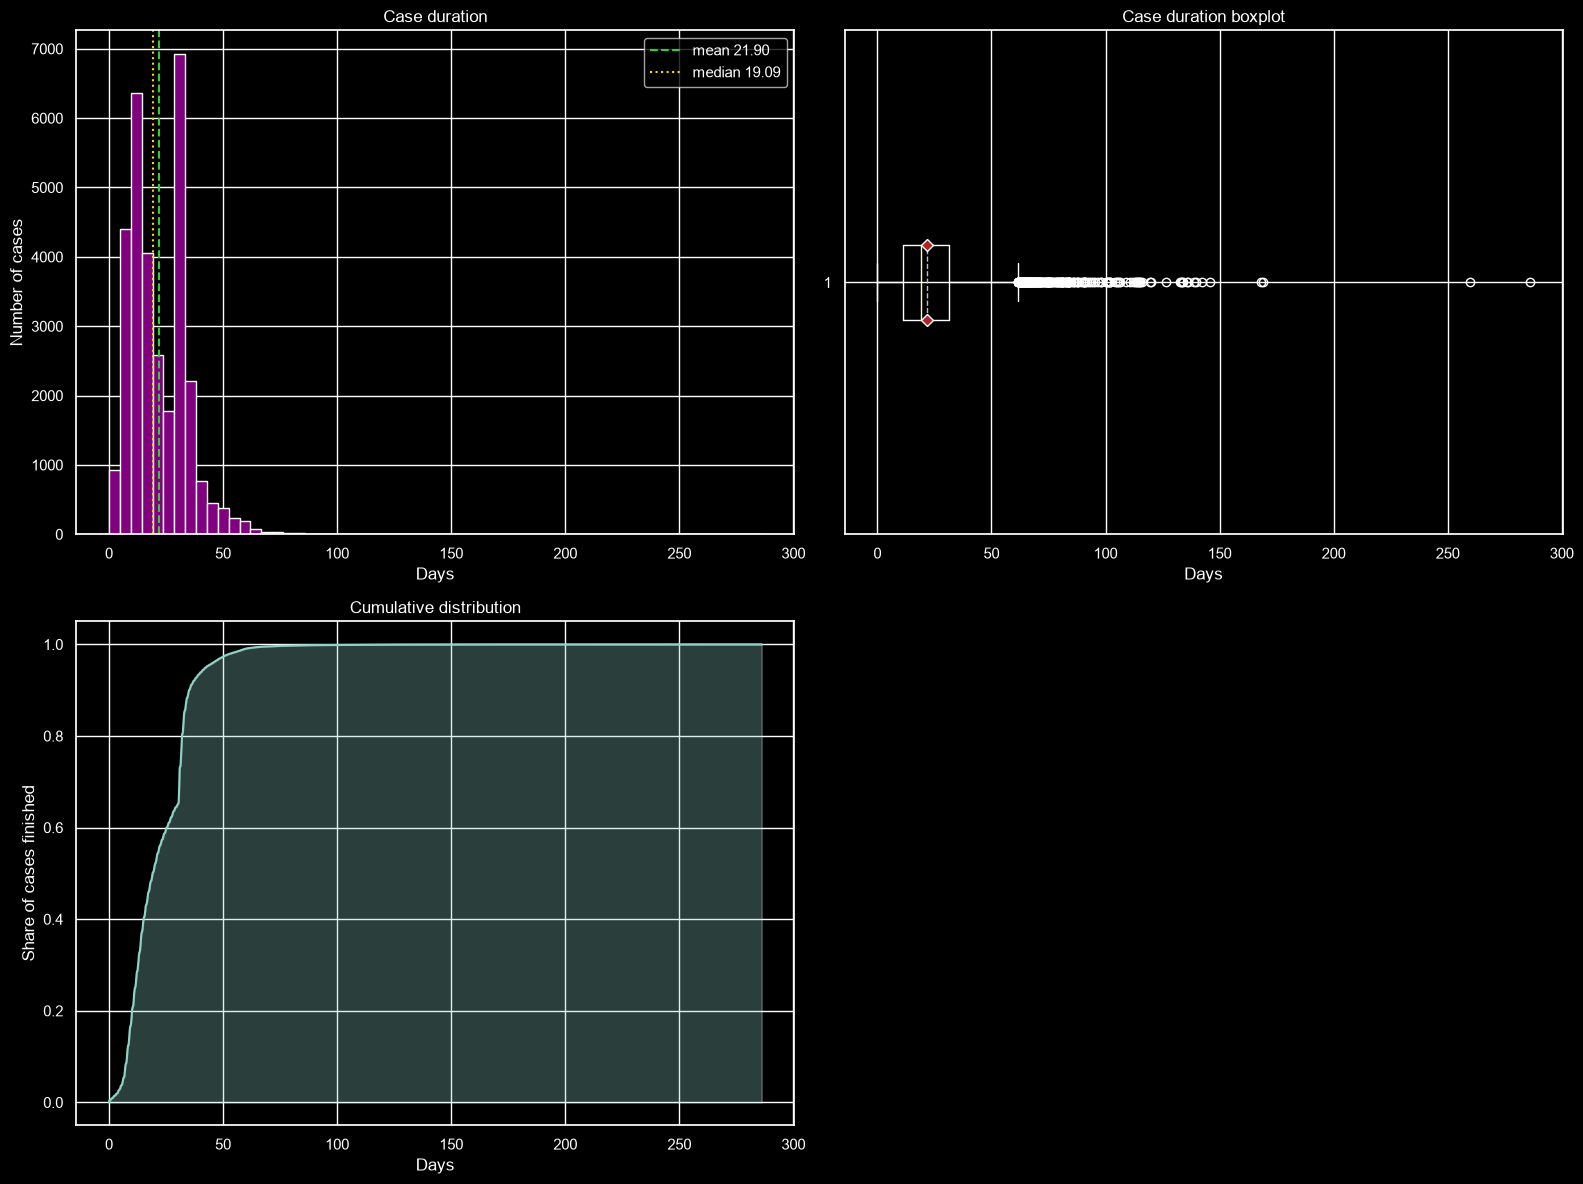

In [ ]:
# Case duration distribution

duration_in_days = cases["duration_days"]

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# For the outcome
order = ["A_Pending",
        "A_Cancelled", 
        "A_Denied", 
        "No decision yet"]
colors = {"A_Pending": "limegreen", 
          "A_Cancelled": "tomato",
          "A_Denied": "gold", 
          "No decision yet": "grey"}

# one duration Series per outcome, in a fixed order
groups = {o: cases.loc[cases["outcome"] == o, "duration_days"] for o in order}

# Histogram
axes[0][0].hist(duration_in_days, 
                bins=60, # Number of bins was chosen using plain sight
                color= "Purple")
axes[0][0].set(title="Case duration",
               xlabel="Days", 
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(), 
                linestyle="--", 
                color="limegreen",
                label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(), 
                linestyle=":", 
                color="gold",
                label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot
meanlineprops = dict(linestyle='-*', 
                     linewidth=2.5, 
                     color='laveander')
meanpointprops = dict(marker = 'D', 
                      markeredgecolor = "white", 
                      markerfacecolor= "firebrick")
axes[0][1].boxplot(duration_in_days, 
                   meanprops = meanpointprops,
                   showmeans = True, 
                   meanline=True,
                   orientation = "horizontal")
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF - Empirical Cumulative Distribution Function
x = np.sort(duration_in_days.values)
y = np.arange(1, len(x)+1)/len(x)
axes[1][0].plot(x, y)
axes[1][0].set(title="Cumulative distribution", 
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].fill_between(x,y, alpha=0.3)

axes[1][1].set_axis_off()

plt.tight_layout()
plt.show()

[Text(0.5, 1.0, 'Case duration boxplot'), Text(0.5, 0, 'Days')]

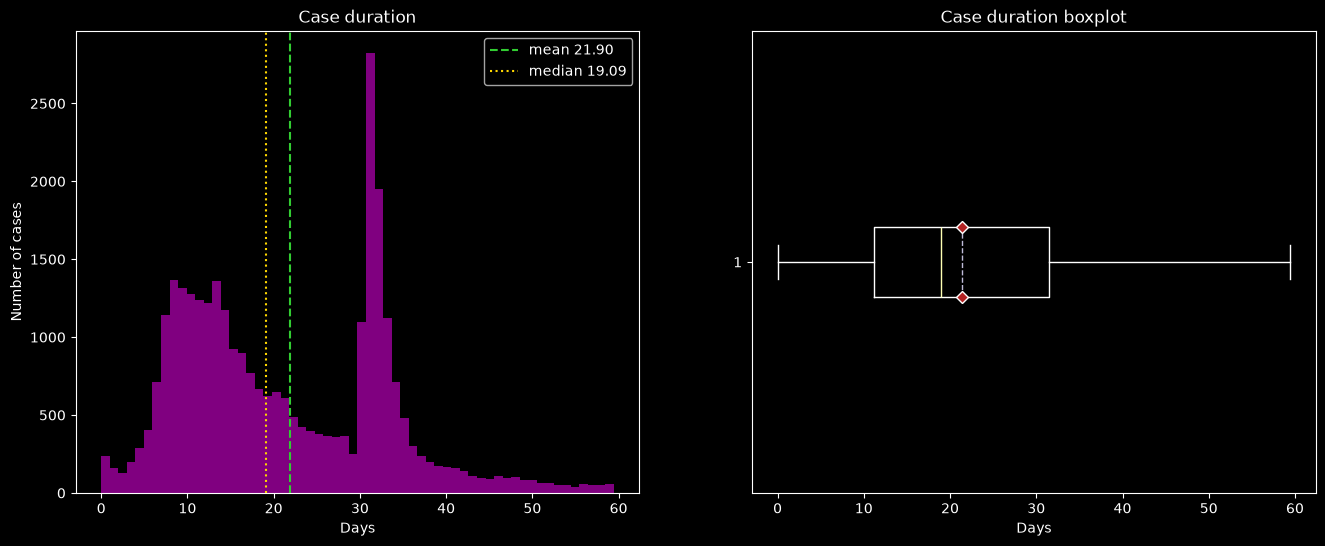

In [20]:
# changes in graphs with percentil 99
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
p99 = duration_in_days.quantile(0.99)
# Histogram
axes[0].hist(duration_in_days[duration_in_days<=p99], 
                bins=60, # Number of bins was chosen using plain sight
                color= "Purple")
axes[0].set(title="Case duration",
               xlabel="Days", 
               ylabel="Number of cases")
axes[0].axvline(duration_in_days.mean(), 
                linestyle="--", 
                color="limegreen",
                label=f"mean {duration_in_days.mean():.2f}")
axes[0].axvline(duration_in_days.median(), 
                linestyle=":", 
                color="gold",
                label=f"median {duration_in_days.median():.2f}")
axes[0].legend()

# Boxplot
meanlineprops = dict(linestyle='-*', 
                     linewidth=2.5, 
                     color='laveander')
meanpointprops = dict(marker = 'D', 
                      markeredgecolor = "white", 
                      markerfacecolor= "firebrick")
axes[1].boxplot(duration_in_days[duration_in_days<=p99], 
                   meanprops = meanpointprops,
                   showmeans = True, 
                   meanline=True,
                   orientation = "horizontal")
axes[1].set(title="Case duration boxplot", xlabel="Days")

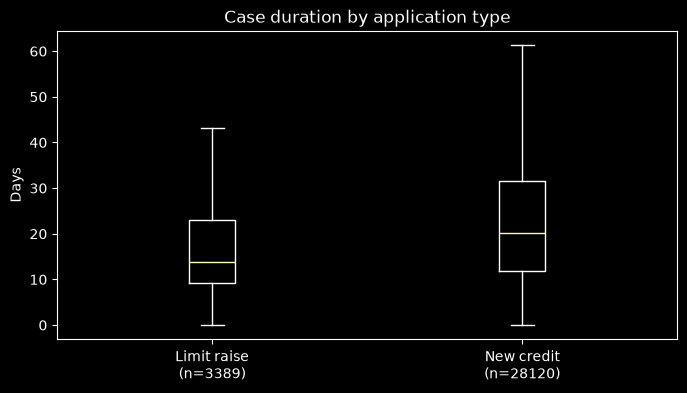

In [21]:
# Outcome analysis by loan attributes

order = cases.groupby("app_type")["duration_days"].median().sort_values().index
data = [cases.loc[cases["app_type"] == k, "duration_days"] for k in order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(data, showfliers=False)
ax.set_xticklabels([f"{k}\n(n={len(v)})" for k, v in zip(order, data)])
ax.set(title="Case duration by application type", ylabel="Days")
plt.show()

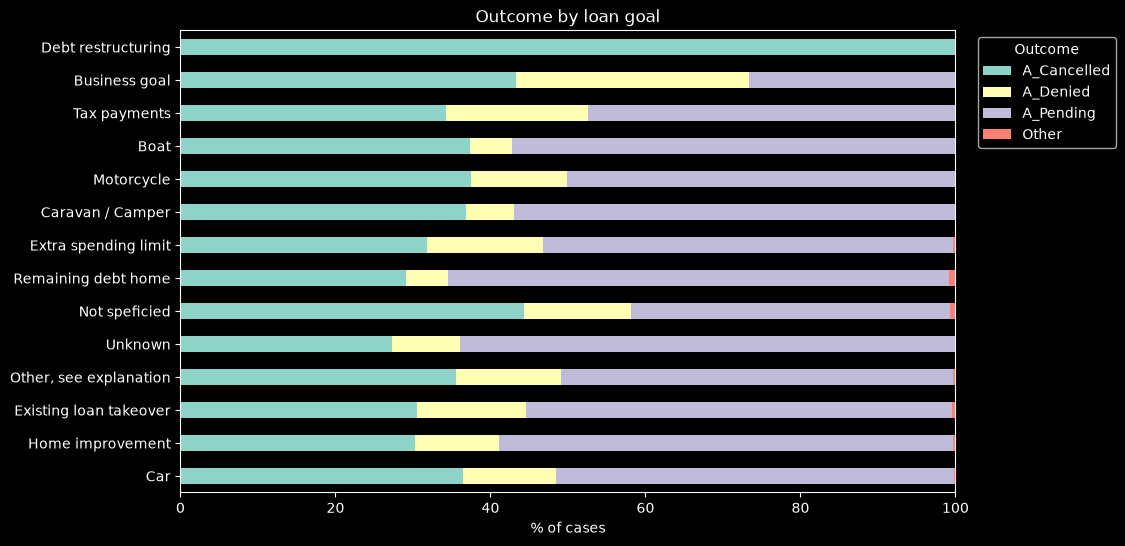

In [ ]:
ct = pd.crosstab(cases["loan_goal"], cases["outcome"], normalize="index") * 100
ct = ct.loc[cases["loan_goal"].value_counts().index]   # biggest groups first

ax = ct.plot(kind="barh", stacked=True, figsize=(10, 6))
ax.set(title="Outcome by loan goal", xlabel="% of cases", ylabel="")
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### **3.3 Process Model Creation and Validation**

In [22]:
# The BPIC-17 log has several lifecycle transitions per activity (start, complete, suspend, and so on),
# A common first design decision is to keep only complete events. You can test both and justify your choice in the report.

log = df[df["lifecycle:transition"] == "complete"].copy()
print(len(log), log["case:concept:name"].nunique())

475306 31509


### **3.4 Advanced Analysis**

#### Option 2: Advanced Data Science Analysis